In [1]:
##A retail company “ABC Private Limited” wants to understand the customer purchase
#  behaviour (specifically, purchase amount) against various products of different categories. 
# They have shared purchase summary of various customers for selected high 
# volume products from last month. The data set also contains customer demographics 
# (age, gender, marital status, city_type, stay_in_current_city), product details 
# (product_id and product category) and Total purchase_amount from last month.
##Now, they want to build a model to predict the purchase amount of customer against various 
# products which will help them to create personalized offer for customers against different products.

In [2]:
##Black Friday Dataset EDA And Feature Engineering
##cleaning and Preparing the data for model training

In [3]:
#datasets
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


In [4]:
import os
print(os.getcwd())

d:\EDA\Black_friday


In [5]:
import os
print(os.listdir())

['black_friday.ipynb']


In [6]:
import os

for root, dirs, files in os.walk(r'D:\EDA'):
    for file in files:
        if file in ['train.csv', 'test.csv']:
            print(os.path.join(root, file))

D:\EDA\data\test.csv
D:\EDA\data\train.csv


In [7]:
import pandas as pd

df_train = pd.read_csv(r'D:\EDA\data\train.csv')
df_test = pd.read_csv(r'D:\EDA\data\test.csv')

print(df_train.head())
print(df_test.head())

   User_ID Product_ID Gender   Age  Occupation City_Category  \
0  1000001  P00069042      F  0-17          10             A   
1  1000001  P00248942      F  0-17          10             A   
2  1000001  P00087842      F  0-17          10             A   
3  1000001  P00085442      F  0-17          10             A   
4  1000002  P00285442      M   55+          16             C   

  Stay_In_Current_City_Years  Marital_Status  Product_Category_1  \
0                          2               0                   3   
1                          2               0                   1   
2                          2               0                  12   
3                          2               0                  12   
4                         4+               0                   8   

   Product_Category_2  Product_Category_3  Purchase  
0                 NaN                 NaN      8370  
1                 6.0                14.0     15200  
2                 NaN                 NaN   

In [8]:
## import the test data
df_test=pd.read_csv(r'D:\EDA\data\test.csv')
df_test.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3
0,1000004,P00128942,M,46-50,7,B,2,1,1,11.0,NaN
1,1000009,P00113442,M,26-35,17,C,0,0,3,5.0,NaN
2,1000010,P00288442,F,36-45,1,B,4+,1,5,14.0,NaN
3,1000010,P00145342,F,36-45,1,B,4+,1,4,9.0,NaN
4,1000011,P00053842,F,26-35,1,C,1,0,4,5.0,12.0


In [9]:
#Merge train and test data
df = pd.concat([df_train, df_test], ignore_index=True)

df.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370.0
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200.0
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422.0
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057.0
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969.0


In [10]:
#Basic
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 783667 entries, 0 to 783666
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     783667 non-null  int64  
 1   Product_ID                  783667 non-null  object 
 2   Gender                      783667 non-null  object 
 3   Age                         783667 non-null  object 
 4   Occupation                  783667 non-null  int64  
 5   City_Category               783667 non-null  object 
 6   Stay_In_Current_City_Years  783667 non-null  object 
 7   Marital_Status              783667 non-null  int64  
 8   Product_Category_1          783667 non-null  int64  
 9   Product_Category_2          537685 non-null  float64
 10  Product_Category_3          237858 non-null  float64
 11  Purchase                    550068 non-null  float64
dtypes: float64(3), int64(4), object(5)
memory usage: 71.7+ MB


In [11]:
df.describe()

,User_ID,Occupation,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
count,7.836670e+05,783667.000000,783667.000000,783667.000000,537685.000000,237858.000000,550068.000000
mean,1.003029e+06,8.079300,0.409777,5.366196,9.844506,12.668605,9263.968713
std,1.727267e+03,6.522206,0.491793,3.878160,5.089093,4.125510,5023.065394
min,1.000001e+06,0.000000,0.000000,1.000000,2.000000,3.000000,12.000000
25%,1.001519e+06,2.000000,0.000000,1.000000,5.000000,9.000000,5823.000000
50%,1.003075e+06,7.000000,0.000000,5.000000,9.000000,14.000000,8047.000000
75%,1.004478e+06,14.000000,1.000000,8.000000,15.000000,16.000000,12054.000000
max,1.006040e+06,20.000000,1.000000,20.000000,18.000000,18.000000,23961.000000


In [12]:
df.drop(['User_ID'],axis=1,inplace=True)

In [13]:
df.head()

,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370.0
1,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200.0
2,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422.0
3,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057.0
4,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969.0


In [152]:
df['Gender'] = pd.get_dummies(df['Gender'],drop_first=True)

In [143]:
##handling the categorical features Gender
df['Gender']=df['Gender'].map({'F':True,'M':False})
df.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,True,NaN,10,A,2,0,3,NaN,NaN,8370.0
1,1000001,P00248942,True,NaN,10,A,2,0,1,6.0,14.0,15200.0
2,1000001,P00087842,True,NaN,10,A,2,0,12,NaN,NaN,1422.0
3,1000001,P00085442,True,NaN,10,A,2,0,12,14.0,NaN,1057.0
4,1000002,P00285442,False,NaN,16,C,4+,0,8,NaN,NaN,7969.0


In [153]:
##handle categorical features Age
df['Age'].unique()

array([nan, '46-50', '26-35', '36-45', '18-25', '51-55', '55+', '0-17'],
      dtype=object)

In [156]:
#pd.get_dummies(df['Age'],drop_first=True)
df['Age']=df['Age'].map({'0-17':1,'18-25':2,'26-35':3,'36-45':4,'46-50':5,'51-55':6,'55+':7})


In [157]:
from sklearn import preprocessing
# labeL_encoder object knows how to understand word Labels.
label_encoder = preprocessing. LabelEncoder()
# Encode labels in column Age
df['Age'] = label_encoder.fit_transform(df['Age'])
df['Age'].unique()

array([7, 4, 2, 3, 1, 5, 6, 0])

In [158]:
df.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,True,7,10,A,2,0,3,NaN,NaN,8370.0
1,1000001,P00248942,True,7,10,A,2,0,1,6.0,14.0,15200.0
2,1000001,P00087842,True,7,10,A,2,0,12,NaN,NaN,1422.0
3,1000001,P00085442,True,7,10,A,2,0,12,14.0,NaN,1057.0
4,1000002,P00285442,False,7,16,C,4+,0,8,NaN,NaN,7969.0


In [25]:
df_city = pd.get_dummies(df['City_Category'],drop_first=True)

In [26]:
df_city.head()

,B,C
0,False,False
1,False,False
2,False,False
3,False,False
4,False,True


In [27]:
pd.concat([df, df_city], axis=1,)
df.head()

,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,P00069042,0,0,10,A,2,0,3,NaN,NaN,8370.0
1,P00248942,0,0,10,A,2,0,1,6.0,14.0,15200.0
2,P00087842,0,0,10,A,2,0,12,NaN,NaN,1422.0
3,P00085442,0,0,10,A,2,0,12,14.0,NaN,1057.0
4,P00285442,1,0,16,C,4+,0,8,NaN,NaN,7969.0


In [38]:
df.columns = df.columns.str.strip()
print(df.columns)

Index(['Product_ID', 'Gender', 'Age', 'Occupation',
       'Stay_In_Current_City_Years', 'Marital_Status', 'Product_Category_1',
       'Product_Category_2', 'Product_Category_3', 'Purchase'],
      dtype='object')


In [40]:
if 'City_Category' in df.columns:
    df.drop('City_Category', axis=1, inplace=True)

In [41]:
df.head()

,Product_ID,Gender,Age,Occupation,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,P00069042,0,NaN,10,2,0,3,NaN,NaN,8370.0
1,P00248942,0,NaN,10,2,0,1,6.0,14.0,15200.0
2,P00087842,0,NaN,10,2,0,12,NaN,NaN,1422.0
3,P00085442,0,NaN,10,2,0,12,14.0,NaN,1057.0
4,P00285442,1,NaN,16,4+,0,8,NaN,NaN,7969.0


In [42]:
##missing values
df.isnull().sum()

Product_ID                         0
Gender                             0
Age                           783667
Occupation                         0
Stay_In_Current_City_Years         0
Marital_Status                     0
Product_Category_1                 0
Product_Category_2            245982
Product_Category_3            545809
Purchase                      233599
dtype: int64

In [47]:
##focus on replacing missing values
df['Product_Category_2'].unique()

array([nan,  6., 14.,  2.,  8., 15., 16., 11.,  5.,  3.,  4., 12.,  9.,
       10., 17., 13.,  7., 18.])

In [48]:
df['Product_Category_2'].value_counts()

Product_Category_2
8.0     91317
14.0    78834
2.0     70498
16.0    61687
15.0    54114
5.0     37165
4.0     36705
6.0     23575
11.0    20230
17.0    19104
13.0    15054
9.0      8177
12.0     7801
10.0     4420
3.0      4123
18.0     4027
7.0       854
Name: count, dtype: int64

In [51]:
df['Product_Category_2'].mode()[0]

np.float64(8.0)

In [54]:
##replace missing values with mode
df['Product_Category_2']=df['Product_Category_2'].fillna(df['Product_Category_2'].mode()[0])

In [55]:
df['Product_Category_2'].isnull().sum()

np.int64(0)

In [57]:
df['Product_Category_2'].value_counts()

Product_Category_2
8.0     337299
14.0     78834
2.0      70498
16.0     61687
15.0     54114
5.0      37165
4.0      36705
6.0      23575
11.0     20230
17.0     19104
13.0     15054
9.0       8177
12.0      7801
10.0      4420
3.0       4123
18.0      4027
7.0        854
Name: count, dtype: int64

In [63]:
df['Product_Category_2'].mode()[0]

np.float64(16.0)

In [65]:
df['Product_Category_3'].unique()

array([nan, 14., 17.,  5.,  4., 16., 15.,  8.,  9., 13.,  6., 12.,  3.,
       18., 11., 10.])

In [66]:
df['Product_Category_3'].value_counts()

Product_Category_3
16.0    46469
15.0    39968
14.0    26283
17.0    23818
5.0     23799
8.0     17861
9.0     16532
12.0    13115
13.0     7849
6.0      6888
18.0     6621
4.0      2691
11.0     2585
10.0     2501
3.0       878
Name: count, dtype: int64

In [67]:
df['Product_Category_3'].mode()[0]

np.float64(16.0)

In [68]:
df['Product_Category_2']=df['Product_Category_3'].fillna(df['Product_Category_3'].mode()[0])

In [69]:
df['Product_Category_3'].isnull().sum()

np.int64(545809)

In [70]:
df['Product_Category_3'].value_counts()

Product_Category_3
16.0    46469
15.0    39968
14.0    26283
17.0    23818
5.0     23799
8.0     17861
9.0     16532
12.0    13115
13.0     7849
6.0      6888
18.0     6621
4.0      2691
11.0     2585
10.0     2501
3.0       878
Name: count, dtype: int64

In [71]:
df['Product_Category_3'].mode()[0]

np.float64(16.0)

In [73]:
df['Product_Category_3'].mode()

0    16.0
Name: Product_Category_3, dtype: float64

In [74]:
df['Product_Category_3'] = df['Product_Category_3'].fillna(df['Product_Category_3'].mode()[0])

In [75]:
df['Product_Category_3'].isnull().sum()

np.int64(0)

In [76]:
print(df['Product_Category_1'].isnull().sum())
print(df['Product_Category_2'].isnull().sum())
print(df['Product_Category_3'].isnull().sum())

0
0
0


In [77]:
df['Product_Category_1'] = df['Product_Category_1'].fillna(df['Product_Category_1'].mode()[0])
df['Product_Category_2'] = df['Product_Category_2'].fillna(df['Product_Category_2'].mode()[0])
df['Product_Category_3'] = df['Product_Category_3'].fillna(df['Product_Category_3'].mode()[0])

In [101]:
df.shape

(783667, 10)

In [102]:
df['Stay_In_Current_City_Years'].unique()

array(['2', '4+', '3', '1', '0'], dtype=object)

In [105]:
df['Stay_In_Current_City_Years'] = df['Stay_In_Current_City_Years'].str.replace('+','')

In [106]:
df.head()

,Product_ID,Gender,Age,Occupation,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,P00069042,0,NaN,10,2,0,3,16.0,16.0,8370.0
1,P00248942,0,NaN,10,2,0,1,14.0,14.0,15200.0
2,P00087842,0,NaN,10,2,0,12,16.0,16.0,1422.0
3,P00085442,0,NaN,10,2,0,12,16.0,16.0,1057.0
4,P00285442,1,NaN,16,4,0,8,16.0,16.0,7969.0


In [107]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 783667 entries, 0 to 783666
Data columns (total 10 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Product_ID                  783667 non-null  object 
 1   Gender                      783667 non-null  int64  
 2   Age                         0 non-null       float64
 3   Occupation                  783667 non-null  int64  
 4   Stay_In_Current_City_Years  783667 non-null  object 
 5   Marital_Status              783667 non-null  int64  
 6   Product_Category_1          783667 non-null  int64  
 7   Product_Category_2          783667 non-null  float64
 8   Product_Category_3          783667 non-null  float64
 9   Purchase                    550068 non-null  float64
dtypes: float64(4), int64(4), object(2)
memory usage: 59.8+ MB


In [110]:
##convert object to integer
df['Stay_In_Current_City_Years'] = df['Stay_In_Current_City_Years'].astype(int)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 783667 entries, 0 to 783666
Data columns (total 10 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Product_ID                  783667 non-null  object 
 1   Gender                      783667 non-null  int64  
 2   Age                         0 non-null       float64
 3   Occupation                  783667 non-null  int64  
 4   Stay_In_Current_City_Years  783667 non-null  int64  
 5   Marital_Status              783667 non-null  int64  
 6   Product_Category_1          783667 non-null  int64  
 7   Product_Category_2          783667 non-null  float64
 8   Product_Category_3          783667 non-null  float64
 9   Purchase                    550068 non-null  float64
dtypes: float64(4), int64(5), object(1)
memory usage: 59.8+ MB


<Axes: xlabel='Age', ylabel='Purchase'>

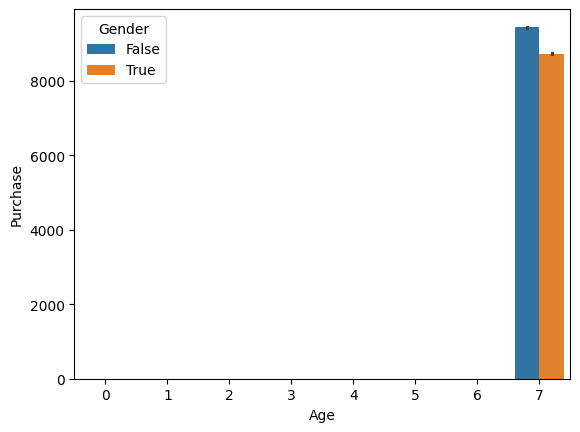

In [164]:
sns.barplot(x='Age', y='Purchase', hue='Gender', data=df)

<Axes: xlabel='Occupation', ylabel='Purchase'>

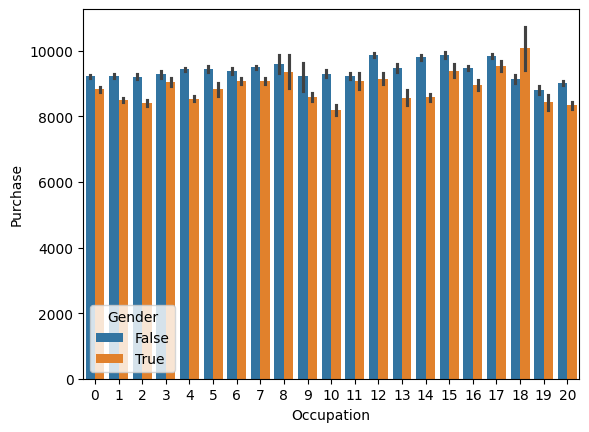

In [165]:
##visualization of purchase with occupation
sns.barplot(x='Occupation', y='Purchase', hue='Gender', data=df)

<Axes: xlabel='Product_Category_1', ylabel='Purchase'>

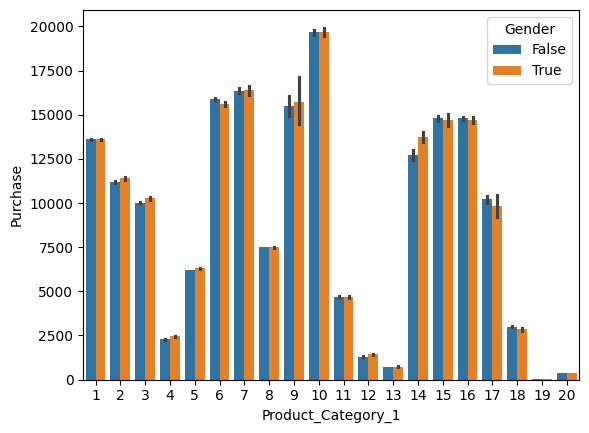

In [166]:
sns.barplot(x='Product_Category_1', y='Purchase', hue='Gender', data=df)

<Axes: xlabel='Product_Category_2', ylabel='Purchase'>

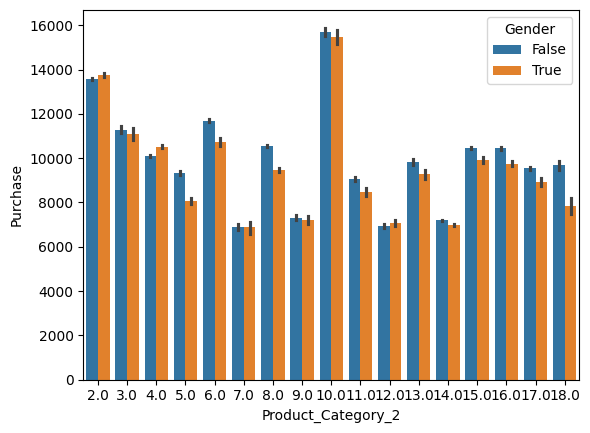

In [167]:
sns.barplot(x='Product_Category_2', y='Purchase', hue='Gender', data=df)

<Axes: xlabel='Product_Category_3', ylabel='Purchase'>

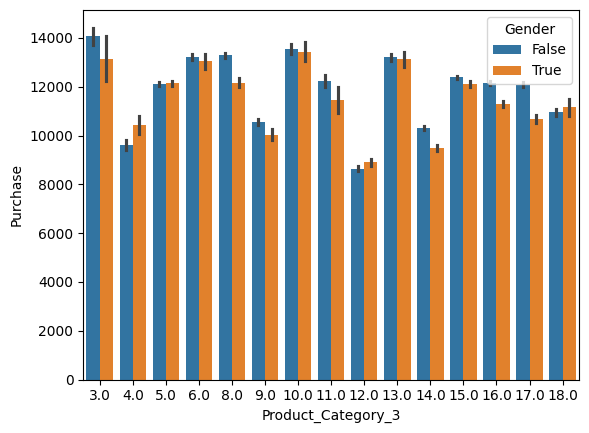

In [168]:
sns.barplot(x='Product_Category_3', y='Purchase', hue='Gender', data=df)

In [169]:
df.head(10)

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,True,7,10,A,2,0,3,NaN,NaN,8370.0
1,1000001,P00248942,True,7,10,A,2,0,1,6.0,14.0,15200.0
2,1000001,P00087842,True,7,10,A,2,0,12,NaN,NaN,1422.0
3,1000001,P00085442,True,7,10,A,2,0,12,14.0,NaN,1057.0
4,1000002,P00285442,False,7,16,C,4+,0,8,NaN,NaN,7969.0
5,1000003,P00193542,False,7,15,A,3,0,1,2.0,NaN,15227.0
6,1000004,P00184942,False,7,7,B,2,1,1,8.0,17.0,19215.0
7,1000004,P00346142,False,7,7,B,2,1,1,15.0,NaN,15854.0
8,1000004,P0097242,False,7,7,B,2,1,1,16.0,NaN,15686.0
9,1000005,P00274942,False,7,20,A,1,1,8,NaN,NaN,7871.0


In [170]:
##feature scaling
df_test=df[df['Purchase'].isnull()]

In [172]:
df_train=df[~df['Purchase'].isnull()]

In [185]:
X=df_train.drop('Purchase', axis=1)

In [175]:
X.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,True,7,10,A,2,0,3,NaN,NaN,8370.0
1,1000001,P00248942,True,7,10,A,2,0,1,6.0,14.0,15200.0
2,1000001,P00087842,True,7,10,A,2,0,12,NaN,NaN,1422.0
3,1000001,P00085442,True,7,10,A,2,0,12,14.0,NaN,1057.0
4,1000002,P00285442,False,7,16,C,4+,0,8,NaN,NaN,7969.0


In [186]:
X.shape

(550068, 11)

In [188]:
y = df_train['Purchase']

In [187]:
y.shape

(550068,)

In [177]:
y

0          8370.0
1         15200.0
2          1422.0
3          1057.0
4          7969.0
           ...   
783662        NaN
783663        NaN
783664        NaN
783665        NaN
783666        NaN
Name: Purchase, Length: 783667, dtype: float64

In [189]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
     X, y, test_size=0.33, random_state=42)

In [195]:
X_train.drop('Product_ID', axis=1, inplace=True, errors='ignore')
X_test.drop('Product_ID', axis=1, inplace=True, errors='ignore')

In [197]:
print(X_train.select_dtypes(include=['object']).columns)

Index(['City_Category', 'Stay_In_Current_City_Years'], dtype='object')


In [198]:
X_train = pd.get_dummies(X_train)
X_test = pd.get_dummies(X_test)

X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

In [199]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [ ]:
##train your model